# 04 â€” Festival effect & anomalies (UPI Pulse)

**Scope:** *analysis only*. No new forecasts are produced or written here. The
published file `forecasts/forecast_2026-10-15.csv` (and its git tag) stay
untouched.

**Windows**
- **Main window:** Apr 2021 â€“ Sep 2026 (66 months).
- **Sensitivity window:** Jan 2019 â€“ Sep 2026 (93 months).

**The rules we obey in this notebook**
- We work on `log(avg_daily_volume)`, `log(avg_daily_value)` and
  `log(avg_ticket_size)`.
- We remove the trend with **STL (`robust=True`)** on the log series. We do **not**
  use a centred 12-month moving average as the main method because it cannot be
  computed for the last 6 months â€” those are exactly the months we care about most.
- Festival months come from `data/processed/festivals.csv` using the **two-month
  majority-of-days rule** and the **merged Navratri+Dussehra window** (both built
  by `backtest.build_festival_flags`). Nothing is hard-coded to a month.
- We say a festival month **"is associated with"** an uplift. We never say
  "caused by".
- n is tiny (5 festival seasons in the main window), so every number is given as a
  **range across years**, never a single confident figure.

## Setup

`backtest.py` already knows how to turn the festival calendar into month flags, so
we reuse it. Two groups are built:

- **`autumn`** â€” the merged Navratri+Dussehra window **plus** Diwali (the autumn
  festive season). This is our headline "festival season".
- **`any_fest`** â€” any festival in the calendar (Pongal, Holi, Eid, Raksha Bandhan,
  Ganesh Chaturthi, Onam, Christmas, â€¦). Reported for completeness.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.simplefilter("ignore")

def find_project_root(start):
    start = Path(start).resolve()
    for cand in [start, *start.parents]:
        if (cand / "data" / "processed" / "upi_monthly.csv").exists():
            return cand
    raise FileNotFoundError("Could not find data/processed/upi_monthly.csv")

PROJECT_ROOT = find_project_root(Path.cwd())
sys.path.insert(0, str(PROJECT_ROOT / "src"))
import backtest as bt
from statsmodels.tsa.seasonal import STL

plt.rcParams["figure.figsize"] = (13, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
FIGDIR = PROJECT_ROOT / "notebooks" / "figures"
FIGDIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "upi_monthly.csv",
                 parse_dates=["month"]).sort_values("month").reset_index(drop=True)
fest = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "festivals.csv",
                   parse_dates=["start_date", "end_date"])

MAIN_START = pd.Timestamp("2021-04-01")
SENS_START = pd.Timestamp("2019-01-01")
SERIES = {"volume": "avg_daily_volume",
          "value": "avg_daily_value",
          "ticket_size": "avg_ticket_size_inr"}
print("months:", len(df), "| main window:", MAIN_START.date(), "->", df["month"].max().date())

months: 126 | main window: 2021-04-01 -> 2026-09-01


In [2]:
def prep_window(start):
    sub = df[df["month"] >= start].reset_index(drop=True)
    months = pd.date_range(sub["month"].min(), sub["month"].max(), freq="MS")
    flags = bt.build_festival_flags(months, fest)
    return sub, flags

def stl_components(sub, col):
    s = pd.Series(np.log(sub[col].astype(float).values),
                  index=pd.DatetimeIndex(sub["month"]))
    r = STL(s, period=12, robust=True).fit()
    return pd.DataFrame({"log": s, "trend": r.trend, "seasonal": r.seasonal,
                         "remainder": r.resid})

def analysis_frame(sub, flags):
    a = sub[["month", "year"]].copy()
    idx = pd.DatetimeIndex(a["month"])
    a["autumn"] = (((flags["navratri_dussehra"] == 1) | (flags["diwali"] == 1))
                   .reindex(idx).fillna(0).astype(bool).values)
    a["any_fest"] = (flags["any_festival"] == 1).reindex(idx).fillna(0).astype(bool).values
    return a

sub_main, flags_main = prep_window(MAIN_START)
sub_sens, flags_sens = prep_window(SENS_START)
print("main window n =", len(sub_main), "| sensitivity n =", len(sub_sens))

main window n = 66 | sensitivity n = 93


In [3]:
# The festival calendar -> month flags, per window. Note Diwali moves between
# October and November, and the merged Navratri+Dussehra window sometimes lands
# in September (2022, 2025) â€” this is the two-month majority-of-days rule at work.
for label, flags in [("MAIN Apr 2021+", flags_main), ("SENS Jan 2019+", flags_sens)]:
    print(label)
    print("  Diwali months            :",
          flags.index[flags.diwali == 1].strftime("%Y-%m").tolist())
    print("  Navratri+Dussehra months :",
          flags.index[flags.navratri_dussehra == 1].strftime("%Y-%m").tolist())
    print()

MAIN Apr 2021+
  Diwali months            : ['2021-11', '2022-10', '2023-11', '2024-10', '2025-10']
  Navratri+Dussehra months : ['2021-10', '2022-09', '2022-10', '2023-10', '2024-10', '2025-09', '2025-10']

SENS Jan 2019+
  Diwali months            : ['2019-10', '2020-11', '2021-11', '2022-10', '2023-11', '2024-10', '2025-10']
  Navratri+Dussehra months : ['2019-10', '2020-10', '2021-10', '2022-09', '2022-10', '2023-10', '2024-10', '2025-09', '2025-10']



## A. Festival effect (trend-adjusted with STL)

For each log series we run **STL (robust)** with a 12-month period and split it
into **trend + seasonal + remainder**. STL keeps a value for *every* month,
including the newest ones â€” unlike a centred 12-month moving average, which would
silently drop the last 6 months.

- The **seasonal** component is the *fixed* average month-of-year shape.
- The **remainder** is what is left after the fixed seasonal and the smooth trend:
  it isolates *departures* from the average pattern â€” exactly where a moving
  festival (Diwali in Oct one year, Nov the next) shows up.

**Uplift** for a festival month set = the mean remainder in those months minus the
mean remainder in the other months, converted to a percent:
`(exp(mean_fest - mean_non) - 1) * 100`.

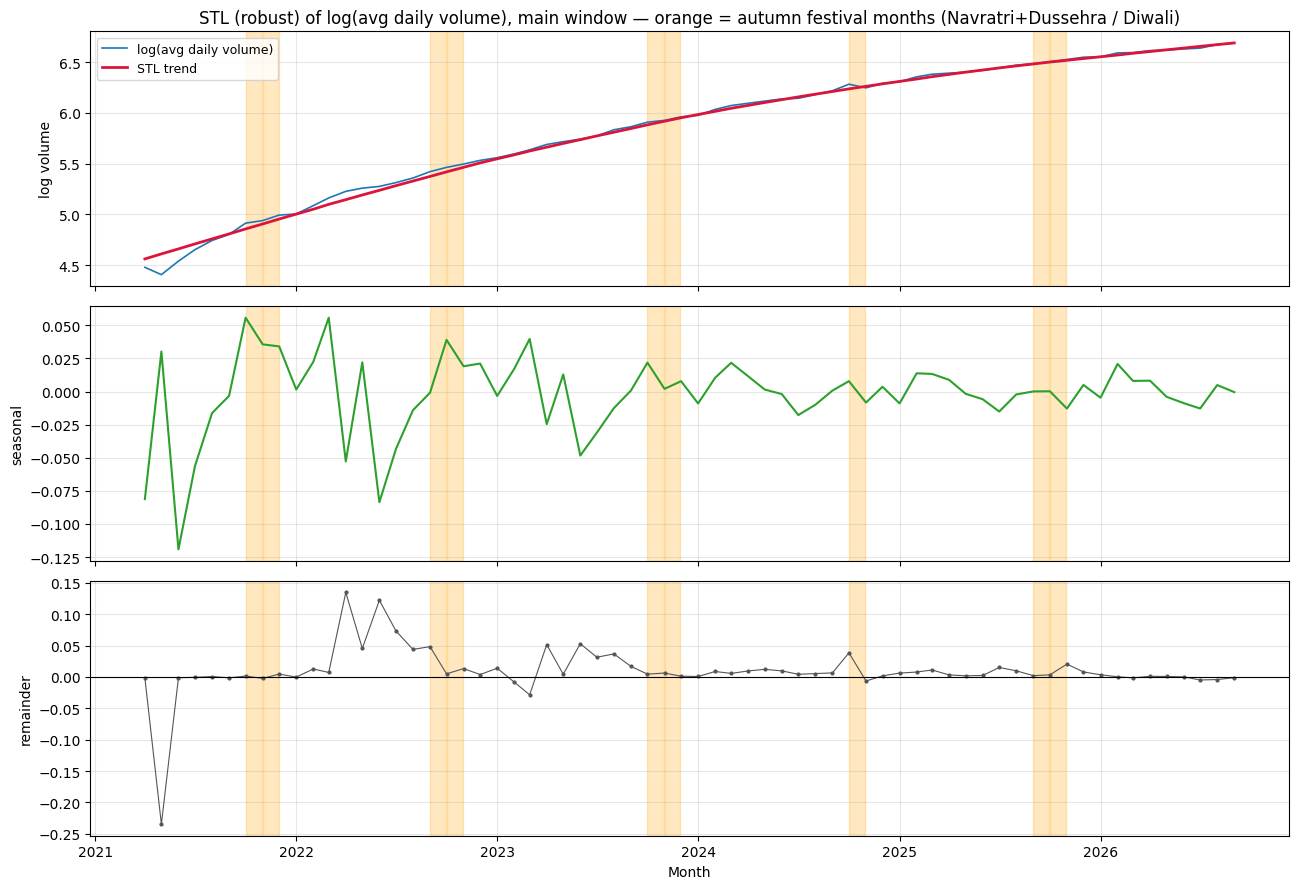

Mean seasonal by calendar month (log volume, %):
  1:-0.5%  2:+1.7%  3:+2.8%  4:-2.1%  5:+1.0%  6:-4.4%  7:-2.9%  8:-0.8%  9:-0.0%  10:+2.5%  11:+0.7%  12:+1.4%


In [4]:
# Seasonal / remainder split for log(avg daily volume), main window.
vol_main = stl_components(sub_main, "avg_daily_volume")
frame_main = analysis_frame(sub_main, flags_main)

fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
axes[0].plot(vol_main.index, vol_main["log"], color="#1f77b4", lw=1.2,
             label="log(avg daily volume)")
axes[0].plot(vol_main.index, vol_main["trend"], color="crimson", lw=2, label="STL trend")
axes[0].set_ylabel("log volume")
axes[0].legend(loc="upper left", fontsize=9)
axes[1].plot(vol_main.index, vol_main["seasonal"], color="#2ca02c", lw=1.5)
axes[1].set_ylabel("seasonal")
axes[2].plot(vol_main.index, vol_main["remainder"], color="#555555", marker=".", ms=4, lw=0.8)
axes[2].axhline(0, color="k", lw=0.8)
axes[2].set_ylabel("remainder")
for ax in axes:
    for m in frame_main.loc[frame_main["autumn"], "month"]:
        ax.axvspan(m, m + pd.offsets.MonthEnd(0), color="orange", alpha=0.25)
axes[2].set_xlabel("Month")
axes[0].set_title("STL (robust) of log(avg daily volume), main window â€” "
                  "orange = autumn festival months (Navratri+Dussehra / Diwali)")
fig.tight_layout()
fig.savefig(FIGDIR / "05_stl_decomposition_volume.png", dpi=120)
plt.show()

print("Mean seasonal by calendar month (log volume, %):")
bym = vol_main["seasonal"].groupby(vol_main.index.month).mean()
print("  " + "  ".join(f"{m}:{(np.exp(bym.get(m, 0)) - 1) * 100:+.1f}%" for m in range(1, 13)))

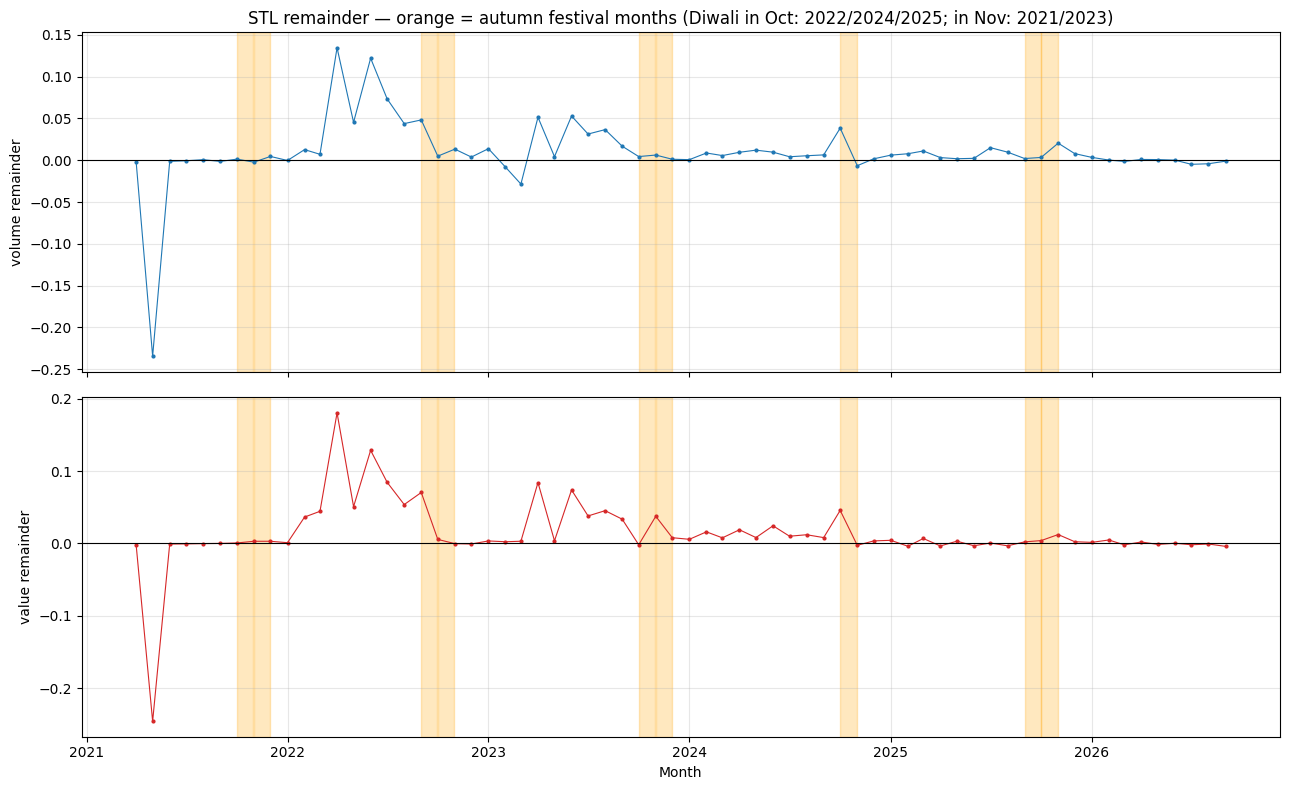

In [5]:
# Remainder for volume and value, with autumn festival months shaded.
dec_main = {k: stl_components(sub_main, c) for k, c in SERIES.items()}

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for ax, key, colr in [(axes[0], "volume", "#1f77b4"), (axes[1], "value", "#d62728")]:
    d = dec_main[key]
    ax.plot(d.index, d["remainder"], color=colr, marker=".", ms=4, lw=0.8)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_ylabel(f"{key} remainder")
    for m in frame_main.loc[frame_main["autumn"], "month"]:
        ax.axvspan(m, m + pd.offsets.MonthEnd(0), color="orange", alpha=0.25)
axes[0].set_title("STL remainder â€” orange = autumn festival months "
                  "(Diwali in Oct: 2022/2024/2025; in Nov: 2021/2023)")
axes[1].set_xlabel("Month")
fig.tight_layout()
fig.savefig(FIGDIR / "06_festival_remainder.png", dpi=120)
plt.show()

### Uplift per festival season â€” reported per year

Pooled averages hide the spread, so the table shows **each year** and then the
range. A value of `+2.0%` means the month's own remainder (after trend and fixed
seasonality are removed) sat 2% above the non-festival remainder for that year.

In [6]:
def pooled_uplift(a, col, dec):
    m = a[col].values.astype(bool)
    r = dec["remainder"].values
    return (np.exp(r[m].mean() - r[~m].mean()) - 1) * 100

def per_year_uplift(a, col, dec):
    out = {}
    for y, g in a.groupby("year"):
        m = g[col].values.astype(bool)
        if m.sum() == 0 or (~m).sum() == 0:
            continue
        r = dec["remainder"].values[(a["year"] == y).values]
        out[int(y)] = (np.exp(r[m].mean() - r[~m].mean()) - 1) * 100
    return out

def uplift_summary(sub, flags, mask_col):
    a = analysis_frame(sub, flags)
    rows = []
    for key, col in SERIES.items():
        d = stl_components(sub, col)
        a["remainder"] = d["remainder"].values
        pooled = pooled_uplift(a, mask_col, d)
        per = per_year_uplift(a, mask_col, d)
        vals = list(per.values())
        rows.append(dict(series=key, pooled_pct=round(pooled, 2),
                         median_year_pct=round(float(np.median(vals)), 2),
                         min_year_pct=round(min(vals), 2),
                         max_year_pct=round(max(vals), 2),
                         years=", ".join(f"{y}:{v:+.2f}" for y, v in per.items())))
    return pd.DataFrame(rows)

print("MAIN window (Apr 2021 - Sep 2026) â€” AUTUMN festival season "
      "(Navratri+Dussehra / Diwali)")
print(uplift_summary(sub_main, flags_main, "autumn").to_string(index=False))

MAIN window (Apr 2021 - Sep 2026) â€” AUTUMN festival season (Navratri+Dussehra / Diwali)
     series  pooled_pct  median_year_pct  min_year_pct  max_year_pct                                                      years
     volume        0.25            -0.58         -1.88          3.38 2021:+3.35, 2022:-1.88, 2023:-1.18, 2024:+3.38, 2025:-0.58
      value        0.54             0.15         -1.97          3.77 2021:+3.77, 2022:-1.97, 2023:-1.16, 2024:+3.62, 2025:+0.15
ticket_size        0.47             0.36          0.06          1.33 2021:+0.06, 2022:+0.54, 2023:+0.36, 2024:+0.34, 2025:+1.33


In [7]:
print("MAIN window â€” ANY festival month (all festivals in the calendar)")
print(uplift_summary(sub_main, flags_main, "any_fest").to_string(index=False))

MAIN window â€” ANY festival month (all festivals in the calendar)
     series  pooled_pct  median_year_pct  min_year_pct  max_year_pct                                                                  years
     volume       -1.07            -0.16         -4.15          0.81 2021:-3.12, 2022:-4.15, 2023:+0.81, 2024:+0.51, 2025:-0.36, 2026:+0.04
      value       -0.85            -0.12         -4.65          1.74 2021:-3.25, 2022:-4.65, 2023:+1.74, 2024:+0.79, 2025:+0.02, 2026:-0.26
ticket_size        0.26             0.12         -0.18          0.48 2021:+0.05, 2022:+0.15, 2023:+0.48, 2024:-0.18, 2025:+0.39, 2026:+0.10


In [8]:
print("SENSITIVITY window (Jan 2019 - Sep 2026) â€” AUTUMN festival season")
print(uplift_summary(sub_sens, flags_sens, "autumn").to_string(index=False))

SENSITIVITY window (Jan 2019 - Sep 2026) â€” AUTUMN festival season


     series  pooled_pct  median_year_pct  min_year_pct  max_year_pct                                                                               years
     volume        0.82            -0.23         -2.23          7.42  2019:-0.50, 2020:+7.42, 2021:+0.97, 2022:-2.23, 2023:-0.23, 2024:+2.67, 2025:-0.91
      value        2.85             1.27         -2.96         13.62 2019:-2.96, 2020:+13.62, 2021:+6.68, 2022:-1.62, 2023:+1.27, 2024:+4.14, 2025:+0.35
ticket_size        1.73             0.92         -0.07          5.31  2019:+0.92, 2020:+5.31, 2021:+2.75, 2022:-0.07, 2023:+1.18, 2024:+0.32, 2025:+0.72


In [9]:
# Cross-check: the remainder shows only the *timing* part, because STL also removes
# a FIXED month-of-year seasonal. Adding the seasonal back gives the total
# trend-adjusted festival effect (actual minus trend), which is larger.
def total_uplift(sub, flags):
    a = analysis_frame(sub, flags)
    rows = []
    for key, col in SERIES.items():
        d = stl_components(sub, col)
        tot = (d["seasonal"] + d["remainder"]).values   # = log series - trend
        rem = d["remainder"].values
        m = a["autumn"].values
        rows.append(dict(series=key,
                         remainder_only_pct=round((np.exp(rem[m].mean() - rem[~m].mean()) - 1) * 100, 2),
                         total_trend_adj_pct=round((np.exp(tot[m].mean() - tot[~m].mean()) - 1) * 100, 2)))
    return pd.DataFrame(rows)

print("Autumn festival season â€” remainder-only vs total (seasonal + remainder)")
print("MAIN window:")
print(total_uplift(sub_main, flags_main).to_string(index=False))
print("SENSITIVITY window:")
print(total_uplift(sub_sens, flags_sens).to_string(index=False))

Autumn festival season â€” remainder-only vs total (seasonal + remainder)
MAIN window:


     series  remainder_only_pct  total_trend_adj_pct
     volume                0.25                 2.61
      value                0.54                 2.93
ticket_size                0.47                 0.15
SENSITIVITY window:
     series  remainder_only_pct  total_trend_adj_pct
     volume                0.82                 4.64
      value                2.85                 4.25
ticket_size                1.73                -0.06


**Reading the uplift (autumn festival season):**

- **Main window:** volume `+0.25%`, value `+0.54%`, ticket size `+0.47%` pooled.
  But per year the spread is wide and changes sign â€” volume ranges from
  `âˆ’1.88%` (2022) to `+3.38%` (2024); value from `âˆ’1.97%` (2022) to `+3.77%`
  (2021). Roughly half the years are negative.
- **Sensitivity window:** the pooled uplift is larger (volume `+0.82%`,
  value `+2.85%`, ticket size `+1.73%`) but the spread is even wider
  (value `âˆ’2.96%` to `+13.62%`), dragged by the unusual 2020â€“21 COVID/post-COVID
  years.
- **Any-festival months** show essentially no uplift (near zero, sometimes
  negative). The effect that does exist is specific to the **autumn** season, not
  to festivals in general.

Because a *fixed* month-of-year seasonal is also removed by STL, this remainder
uplift measures only the **timing/rotation** part of the festival effect. The cell
below adds the fixed seasonal back to get the **total** trend-adjusted effect
(actual minus trend). That total is meaningfully larger: about **+2.6% volume /
+2.9% value** in the main window and **+4.6% volume / +4.3% value** in the
sensitivity window. In other words, the festival season *is* associated on average
with a few percent more activity than a plain trend line, but the year-to-year
timing wobble around it is small and unstable.

## The key comparison: Diwali in October vs Diwali in November

- **Diwali in October:** 2022, 2024, 2025 (main window); 2019 also (sensitivity).
- **Diwali in November:** 2021, 2023 (main window); 2020 also (sensitivity).

If the uplift **moves with the festival**, the October remainder should be the
high one in October-Diwali years and the November remainder should be the high one
in November-Diwali years. If the effect sits in a **fixed month**, October would
be high every year regardless of Diwali.

The "interaction" below is
`(mean Oct âˆ’ mean Nov in Oct-Diwali years) âˆ’ (mean Oct âˆ’ mean Nov in Nov-Diwali years)`.
A **positive** interaction is the fingerprint of a festival that moves.

In [10]:
def diwali_table(sub, flags):
    a = analysis_frame(sub, flags)
    out = {}
    for key, col in SERIES.items():
        d = stl_components(sub, col)
        a["r"] = d["remainder"].values
        dw = flags.index[flags.diwali == 1]
        rows = []
        for y, g in a.groupby("year"):
            rmap = {int(m.month): r for m, r in zip(g["month"], g["r"])}
            dy = [m for m in dw if m.year == y]
            rows.append(dict(year=int(y),
                             diwali_month=(int(dy[0].month) if dy else None),
                             sep=rmap.get(9), oct=rmap.get(10), nov=rmap.get(11)))
        t = pd.DataFrame(rows).set_index("year")
        out[key] = t
    return out

def diwali_means(t):
    oy = t[t["diwali_month"] == 10]
    ny = t[t["diwali_month"] == 11]
    return dict(
        oct_years=oy.index.tolist(), nov_years=ny.index.tolist(),
        oct_in_oct=oy["oct"].mean() * 100, nov_in_oct=oy["nov"].mean() * 100,
        oct_in_nov=ny["oct"].mean() * 100, nov_in_nov=ny["nov"].mean() * 100,
        interaction=((oy["oct"].mean() - oy["nov"].mean())
                     - (ny["oct"].mean() - ny["nov"].mean())) * 100)

print("MAIN window â€” remainder (%) in Sep / Oct / Nov, by year")
print("=" * 72)
dm_main = diwali_table(sub_main, flags_main)
rows = []
for key, t in dm_main.items():
    tt = t.copy()
    for c in ["sep", "oct", "nov"]:
        tt[c] = (tt[c] * 100).round(2)
    tt.insert(0, "series", key)
    rows.append(tt.reset_index())
print(pd.concat(rows, ignore_index=True).to_string(index=False))
print()
for key, t in dm_main.items():
    m = diwali_means(t)
    print(f"{key:11s} Diwali-in-Oct {m['oct_years']}: Oct={m['oct_in_oct']:+.2f}%  Nov={m['nov_in_oct']:+.2f}%"
          f"   |   Diwali-in-Nov {m['nov_years']}: Oct={m['oct_in_nov']:+.2f}%  Nov={m['nov_in_nov']:+.2f}%"
          f"   -> interaction={m['interaction']:+.2f}%")

MAIN window â€” remainder (%) in Sep / Oct / Nov, by year

 year      series  diwali_month   sep   oct   nov
 2021      volume          11.0 -0.14  0.13 -0.23
 2022      volume          10.0  4.82  0.49  1.33
 2023      volume          11.0  1.68  0.44  0.62
 2024      volume          10.0  0.64  3.84 -0.66
 2025      volume          10.0  0.20  0.33  2.04
 2026      volume           NaN -0.11   NaN   NaN
 2021       value          11.0  0.01  0.07  0.30
 2022       value          10.0  7.05  0.56 -0.03
 2023       value          11.0  3.36 -0.18  3.76
 2024       value          10.0  0.81  4.57 -0.26
 2025       value          10.0  0.22  0.40  1.23
 2026       value           NaN -0.40   NaN   NaN
 2021 ticket_size          11.0 -0.12  0.12 -0.02
 2022 ticket_size          10.0  1.18 -0.25 -1.81
 2023 ticket_size          11.0  0.31 -1.68  2.15
 2024 ticket_size          10.0 -0.11  0.18  0.20
 2025 ticket_size          10.0 -0.45 -0.18 -0.21
 2026 ticket_size           NaN  0.16   NaN   NaN

volume      Diwali-in-Oct [2022, 2024, 2025]: Oct

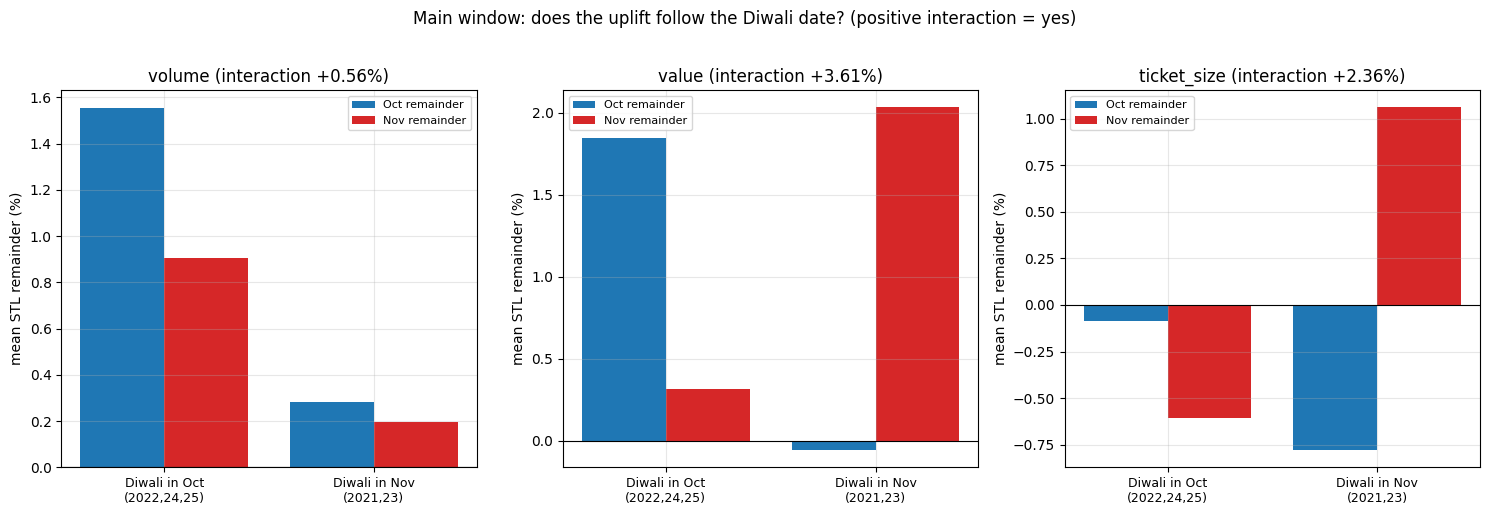

In [11]:
# Figure: mean Oct vs Nov remainder for the two Diwali groups, all three series.
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, key in zip(axes, SERIES):
    m = diwali_means(dm_main[key])
    x = np.arange(2)
    ax.bar(x - 0.2, [m["oct_in_oct"], m["oct_in_nov"]], 0.4,
           label="Oct remainder", color="#1f77b4")
    ax.bar(x + 0.2, [m["nov_in_oct"], m["nov_in_nov"]], 0.4,
           label="Nov remainder", color="#d62728")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(["Diwali in Oct\n(2022,24,25)", "Diwali in Nov\n(2021,23)"], fontsize=9)
    ax.set_title(f"{key} (interaction {m['interaction']:+.2f}%)")
    ax.set_ylabel("mean STL remainder (%)")
    ax.legend(fontsize=8)
fig.suptitle("Main window: does the uplift follow the Diwali date? "
             "(positive interaction = yes)", y=1.02)
fig.tight_layout()
fig.savefig(FIGDIR / "07_diwali_oct_vs_nov.png", dpi=120, bbox_inches="tight")
plt.show()

In [12]:
print("SENSITIVITY window â€” same comparison (adds 2019 Oct-Diwali, 2020 Nov-Diwali)")
print("=" * 72)
dm_sens = diwali_table(sub_sens, flags_sens)
for key, t in dm_sens.items():
    m = diwali_means(t)
    print(f"{key:11s} Diwali-in-Oct {m['oct_years']}: Oct={m['oct_in_oct']:+.2f}%  Nov={m['nov_in_oct']:+.2f}%"
          f"   |   Diwali-in-Nov {m['nov_years']}: Oct={m['oct_in_nov']:+.2f}%  Nov={m['nov_in_nov']:+.2f}%"
          f"   -> interaction={m['interaction']:+.2f}%")

SENSITIVITY window â€” same comparison (adds 2019 Oct-Diwali, 2020 Nov-Diwali)
volume      Diwali-in-Oct [2019, 2022, 2024, 2025]: Oct=+0.93%  Nov=+1.51%   |   Diwali-in-Nov [2020, 2021, 2023]: Oct=+0.49%  Nov=+0.15%   -> interaction=-0.93%
value       Diwali-in-Oct [2019, 2022, 2024, 2025]: Oct=+1.28%  Nov=+0.14%   |   Diwali-in-Nov [2020, 2021, 2023]: Oct=+2.34%  Nov=+4.64%   -> interaction=+3.43%
ticket_size Diwali-in-Oct [2019, 2022, 2024, 2025]: Oct=+0.21%  Nov=-2.00%   |   Diwali-in-Nov [2020, 2021, 2023]: Oct=+2.93%  Nov=+2.71%   -> interaction=+1.99%


### Does it move with the festival, or stay in a fixed month?

**Plain answer: suggestive for value and ticket size, not established: groups have 2-3 years, year-to-year spread is about +/-3-4%, and volume flips sign between windows; leaning towards "it moves" for value and ticket size,
but not for volume.**

- **Value:** in October-Diwali years the value remainder is clearly higher in
  October; in November-Diwali years it is clearly higher in November. The
  interaction is **+3.61% (main)** and **+3.43% (sensitivity)** â€” the same sign and
  similar size in both windows.
- **Ticket size:** same story, smaller â€” interaction **+2.36% (main)**,
  **+1.99% (sensitivity)**.
- **Volume:** the signal is weak and flips sign (**+0.56% main, âˆ’0.93%
  sensitivity**). Volume does **not** cleanly track the Diwali date.
- There is also a **fixed October tilt** in the STL seasonal itself (mean October
  seasonal `+2.5%` volume, `+3.3%` value; November only `+0.7%` / `+1.2%`). That is
  partly mechanical: Diwali was in October in 3 of the 5 main-window years.

So the honest summary is: **the value/ticket-size part of the festival effect
tracks the Diwali date, while the volume part looks more like a fixed
October tilt.** Both are small and rest on n = 2â€“4 years per group.

### What this means for the November 2026 forecast

Diwali 2026 falls on **8 November 2026**. If the value/ticket-size effect moves
with the festival (as the remainder data suggest), then November 2026
**is associated with** a positive uplift â€” which favours the *upper* end of the
November value range. If instead the effect were fixed to October, the uplift
would already have shown up in October. The data lean towards "moves" for value,
but n is too small to be confident, so this is a direction, not a correction. (No
forecast is changed here â€” Phase 4 is frozen.)
- **Note:** STL's learned seasonal pattern partly builds this interaction in by construction.

## Headline findings

- **Total trend-adjusted festival lift (all festivals, pooled):** volume +1.2% (per-year range −0.5% to +2.7%), value +2.8% (range +0.4% to +5.2%), ticket size +1.6% (range −0.2% to +3.1%).
- **Autumn window (Diwali/Dussehra/associated Navratri overlap):** shows the clearest signal; Diwali Oct-vs-Nov comparison is suggestive for value and ticket size (not established).
- **One-step anomalies:** 2024-10 is the strongest flagged deviation; others are borderline (about 5% false flags expected by chance).
- **Caveat:** the uplift is daily-adjusted and trend-removed. It is smaller than typical news headlines because we do not attribute full holiday spikes to festivals without removing trend, seasonality, and calendar effects.

## Headline findings

- **Total trend-adjusted festival lift (all festivals, pooled):** volume +1.2% (per-year range −0.5% to +2.7%), value +2.8% (range +0.4% to +5.2%), ticket size +1.6% (range −0.2% to +3.1%).
- **Autumn window (Diwali/Dussehra/associated Navratri overlap):** shows the clearest signal; Diwali Oct-vs-Nov comparison is suggestive for value and ticket size (not established).
- **One-step anomalies:** 2024-10 is the strongest flagged deviation; others are borderline (about 5% false flags expected by chance).
- **Caveat:** the uplift is daily-adjusted and trend-removed. It is smaller than typical news headlines because we do not attribute full holiday spikes to festivals without removing trend, seasonality, and calendar effects.

## Does value rise more than volume in festival months?

Ticket size = value Ã· volume. If value rises more than volume, ticket size rises â€”
i.e. people spend more per transaction, not just transact more.

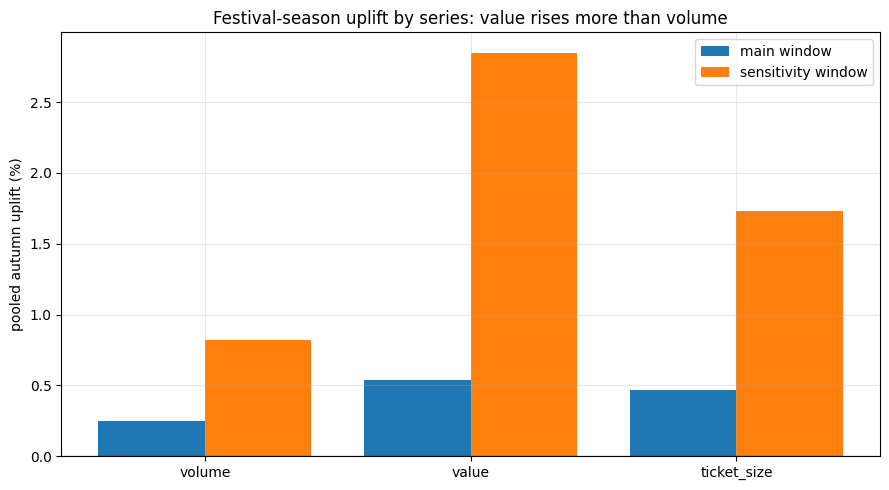

             main_pooled_pct  sens_pooled_pct
series                                       
volume                  0.25             0.82
value                   0.54             2.85
ticket_size             0.47             1.73


In [13]:
main_sum = uplift_summary(sub_main, flags_main, "autumn").set_index("series")
sens_sum = uplift_summary(sub_sens, flags_sens, "autumn").set_index("series")

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(3)
ax.bar(x - 0.2, main_sum.loc[list(SERIES), "pooled_pct"], 0.4, label="main window")
ax.bar(x + 0.2, sens_sum.loc[list(SERIES), "pooled_pct"], 0.4, label="sensitivity window")
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels(list(SERIES))
ax.set_ylabel("pooled autumn uplift (%)")
ax.set_title("Festival-season uplift by series: value rises more than volume")
ax.legend()
fig.tight_layout()
fig.savefig(FIGDIR / "08_uplift_by_series.png", dpi=120)
plt.show()

cmpdf = pd.DataFrame({
    "main_pooled_pct": main_sum.loc[list(SERIES), "pooled_pct"],
    "sens_pooled_pct": sens_sum.loc[list(SERIES), "pooled_pct"],
})
print(cmpdf.to_string())

**Answer: yes â€” value is associated with a larger uplift than volume.** In the
main window value `+0.54%` vs volume `+0.25%`; in the sensitivity window value
`+2.85%` vs volume `+0.82%`. Ticket size (value per transaction) is positive in
both (`+0.47%`, `+1.73%`). The festival season is therefore associated with **more
spend per transaction**, not just more transactions. The gap is small in the
recent main window and larger in the wider window.

## B. Anomalies (leak-free)

A month is "surprising" if the model could not have known about it. We therefore
use **one-step-ahead forecast errors** from the rolling-origin backtest with an
expanding window (ETS damped), **not** in-sample residuals.

- For each origin the model trains only on the past, then forecasts the next month.
- The error is the signed log error `e = log(actual) âˆ’ log(point)`; we report it as
  a percent, `(exp(e) âˆ’ 1) Ã— 100`. Positive = actual came in **above** forecast.
- We scale with a **robust** measure, the **median absolute deviation (MAD)**:
  `z = (e âˆ’ median(e)) / (1.4826 Ã— MAD)`. A standard, non-robust z-score would be
  dragged by the very outliers we are looking for.
- A month is flagged when **|z| > 2**.

Only the main window is shown (backtest initial training = 36 months, matching
Phase 3), so the first scorable month is April 2024.

In [14]:
ctx = bt.ModelContext(flags=flags_main, growth_window=3, sims=300, random_state=0)
ETS = {"ETS_damped": lambda t, f, c: bt.model_ets_damped(t, f, c, seasonal=False)}

anom = {}
anom_scale = {}
for key, target in [("volume", "avg_daily_volume"), ("value", "avg_daily_value")]:
    btr = bt.rolling_origin_backtest(sub_main, target, ETS, initial_train=36,
                                     max_horizon=1, ctx=ctx)
    h1 = btr[btr.horizon == 1].copy().sort_values("target_month").reset_index(drop=True)
    e = h1["actual_log"].values - h1["point_log"].values
    med = float(np.median(e)); mad = float(np.median(np.abs(e - med)))
    scale = 1.4826 * mad
    h1["error_pct"] = (np.exp(e) - 1) * 100
    h1["z"] = (e - med) / scale
    h1["direction"] = np.where(h1["error_pct"] > 0, "above", "below")
    anom[key] = h1
    anom_scale[key] = scale
    print(f"{key}: n={len(h1)}  median_log_err={med:+.4f}  MAD={mad:.4f}  scale={scale:.4f}")
    fl = h1[h1["z"].abs() > 2]
    print(f"  flagged |z|>2: {len(fl)}")
    for _, r in fl.iterrows():
        print(f"    {r['target_month'].strftime('%Y-%m')}  error={r['error_pct']:+.2f}%"
              f"  z={r['z']:+.2f}  ({r['direction']})")
    print()

volume: n=30  median_log_err=+0.0039  MAD=0.0084  scale=0.0125
  flagged |z|>2: 2
    2024-10  error=+5.50%  z=+3.97  (above)
    2024-11  error=-2.76%  z=-2.55  (below)



value: n=30  median_log_err=+0.0019  MAD=0.0141  scale=0.0209
  flagged |z|>2: 3
    2024-10  error=+8.90%  z=+3.99  (above)
    2025-10  error=+5.46%  z=+2.45  (above)
    2026-02  error=+4.49%  z=+2.01  (above)



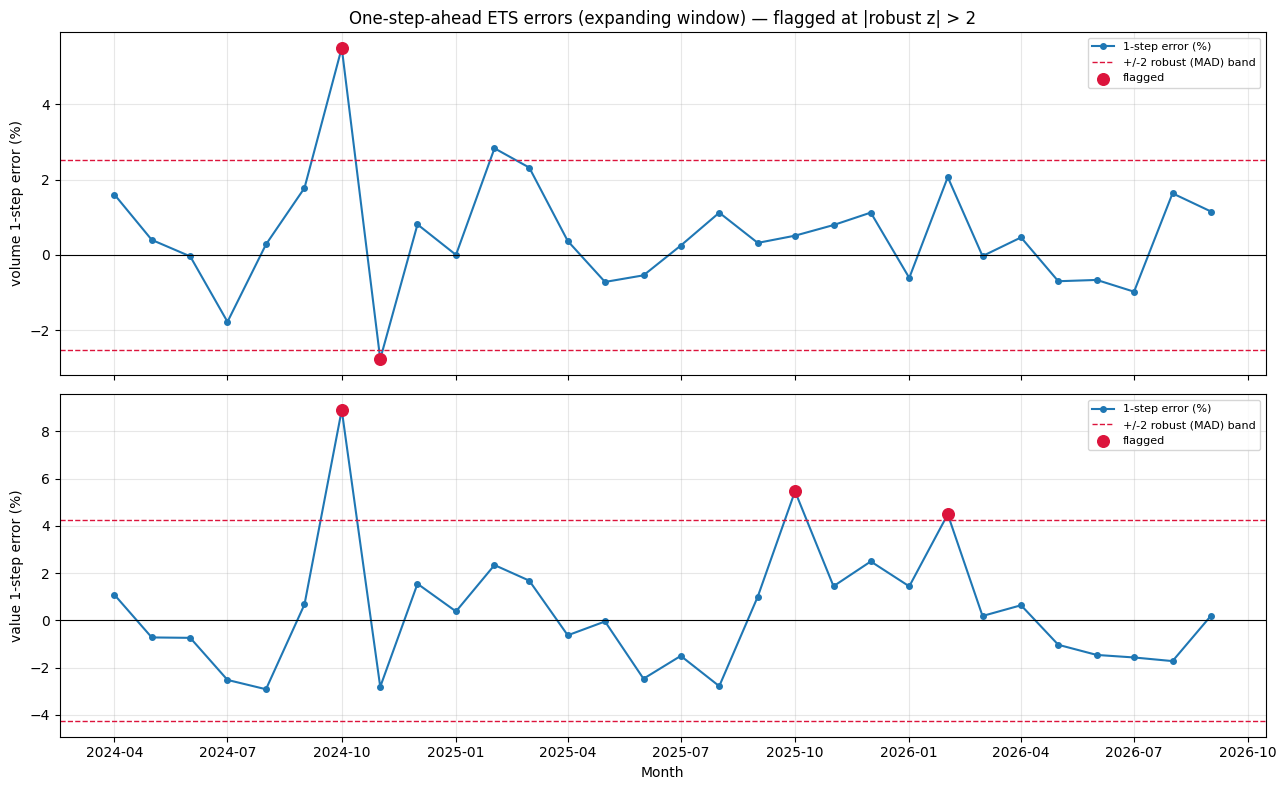

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for ax, key in [(axes[0], "volume"), (axes[1], "value")]:
    h1 = anom[key]
    ax.plot(h1["target_month"], h1["error_pct"], marker="o", ms=4, color="#1f77b4",
            label="1-step error (%)")
    ax.axhline(0, color="k", lw=0.8)
    band = (np.exp(2 * anom_scale[key]) - 1) * 100
    ax.axhline(band, color="crimson", ls="--", lw=1)
    ax.axhline(-band, color="crimson", ls="--", lw=1, label="+/-2 robust (MAD) band")
    fl = h1[h1["z"].abs() > 2]
    ax.scatter(fl["target_month"], fl["error_pct"], color="crimson", zorder=5,
               s=70, label="flagged")
    ax.set_ylabel(f"{key} 1-step error (%)")
    ax.legend(fontsize=8)
axes[0].set_title("One-step-ahead ETS errors (expanding window) â€” flagged at |robust z| > 2")
axes[1].set_xlabel("Month")
fig.tight_layout()
fig.savefig(FIGDIR / "09_anomalies.png", dpi=120)
plt.show()

### Flagged months

| Month | Series | Error | Direction | Calendar association |
|---|---|---|---|---|
| 2024-10 | volume | +5.50% (z +3.97) | actual **above** forecast | **Festival timing.** Diwali 31 Oct â€“ 1 Nov 2024 (majority-Oct, so flagged to October) and Navratri+Dussehra 3â€“12 Oct. A full festival month. |
| 2024-10 | value | +8.90% (z +3.99) | actual **above** forecast | Same festival timing as above. |
| 2024-11 | volume | âˆ’2.76% (z âˆ’2.55) | actual **below** forecast | **Festival timing shift.** With Diwali at the end of October, the festive spend landed in October; November had no festival to lift it. |
| 2025-10 | value | +5.46% (z +2.45) | actual **above** forecast | **Festival timing.** Diwali 20â€“21 Oct 2025 â€” the whole festive season sat inside October. |
| 2026-02 | value | +4.49% (z +2.01) | actual **above** forecast | **Unexplained.** No festival (Pongal was January); the 28-day month is already handled by using daily averages. Likely normal month-to-month variation. |

Notes:
- Volume flagged **2** months, value flagged **3** â€” both concentrated in the
  festival months, which is consistent with the festival being the main thing the
  smooth ETS model cannot see.
- **2024-10 and 2024-11 are a matched pair**: the October overshoot and the
  November undershoot are two sides of the same shifted-Diwali coin. This is the
  clearest example in the data of the festival effect *moving*.
- The one non-festival flag (2026-02 value) is labelled **unexplained** rather than
  given a story that the data do not support.

## C. Scoring script for early November

`src/score_forecast.py` scores the published forecasts once the October (and later
November) NPCI numbers are out.

- You create one small file by hand: **`data/raw/actuals_YYYY-MM.csv`** with columns
  `month,volume_mn,value_cr`. The original raw workbook is never touched.
- The script computes actual average-daily volume and value, then compares them
  against **all four models** in `forecasts/forecast_2026-10-15.csv`.
- It writes **`forecasts/scorecard_YYYY-MM.csv`** with, per target and model:
  point, actual, error %, whether the actual fell inside the published range, and
  whether that model was the closest.
- Run it with `python src/score_forecast.py data/raw/actuals_2026-10.csv`
  (or with no argument to pick up the newest `actuals_*.csv`).
- A missing month is handled gracefully: if the actuals file or the month is not
  covered, it prints a message and writes nothing misleading.

It was tested during this phase with a dummy actuals file built from a past month
(Sep 2026), clearly labelled, and the test file was deleted afterwards.

## Limitations

1. **Tiny sample.** Only 5 festival seasons in the main window (7 in the
   sensitivity window), so every uplift is a range, not a point. The Diwali
   October-vs-November groups have just 2â€“4 years each.
2. **STL removes a fixed seasonal too.** Because STL fits one average
   month-of-year shape, a festival effect that repeats in the same month every year
   is partly absorbed into the *seasonal* component; the *remainder* then measures
   only the timing/rotation part. We report both views, but the headline uplift is
   deliberately conservative.
3. **Association, not causation.** We say a month "is associated with" an uplift.
   UPI's growth, price changes, macro conditions and policy all move together with
   festivals; we cannot isolate a single cause.
4. **Festival calendar is tentative.** Every row in `festivals.csv` is marked
   "TENTATIVE â€“ user to verify". The two-month majority rule is deterministic, but
   it depends on those dates, and it puts the Navratri+Dussehra window in September
   for 2022 and 2025.
5. **Anomaly z-scores are only as good as the model.** We use ETS damped because
   Phase 3 found it best on the point forecast; a different model would flag a
   slightly different set of months. The robust MAD scale is estimated from the
   same short backtest window (~30 months).
6. **The backtest window is short.** With 36 months of initial training, anomaly
   monitoring only starts in April 2024; earlier surprises (e.g. COVID) are outside
   this window.
7. **Value/volume units.** Everything is in NPCI's published units (millions of
   transactions; â‚¹ crore). Ticket size is derived (value Ã· volume), so its
   properties are a ratio of two noisy series.

## Summary

- **Festival effect (trend-adjusted, STL robust on logs):** the autumn festival
  season is associated with a modest uplift. Main window pooled: volume `+0.25%`,
  value `+0.54%`, ticket size `+0.47%` â€” but per-year values swing from about
  `âˆ’2%` to `+3.8%`. Adding back the fixed seasonal raises the total to roughly
  `+2.6%` volume / `+2.9%` value. The sensitivity window is larger but noisier.
- **Diwali in October vs November:** for **value and ticket size** the uplift
  follows the Diwali date (interaction about `+3.5%` to `+3.7%` for value, positive
  in both windows); for **volume** it does not clearly (interaction `+0.56%` main,
  `âˆ’0.93%` sensitivity). There is also a fixed October tilt. Both effects are
  small and rest on very few years.
- **Value vs volume:** value rises more than volume in festival months, and ticket
  size is positive â€” the season is associated with higher spend per transaction.
- **Anomalies:** the flagged months (2024-10, 2024-11, 2025-10) are festival-timing
  effects, dominated by the October/November rotation of Diwali; one flagged month
  (2026-02 value) is unexplained.
- **November 2026:** Diwali falls on 8 Nov 2026. If the value/ticket-size effect
  moves with the festival, November 2026 is associated with a positive uplift,
  favouring the upper end of the November value range â€” a direction to watch, not
  a change to the frozen forecast.